# Comparación de algoritmos de aprendizaje supervisado: KNN, SVM y MLP

Práctica de clasificación de tumores de mama (benignos vs. malignos) que implementa y compara tres algoritmos de aprendizaje supervisado sobre un mismo conjunto de datos y una misma división de entrenamiento y prueba.

## Objetivo

Comprender las diferencias entre K-Nearest Neighbors (KNN), Support Vector Machine (SVM) y una red neuronal artificial (MLP), evaluar su rendimiento y determinar cuál ofrece mejores resultados para un problema de clasificación médica.


### Integrante 1: Carga y exploración de datos

Cantidad de registros: 569
Cantidad de columnas: 32
Variables predictoras: 30 (se excluyen 'id' y 'diagnosis')
Valores nulos totales: 0

Clases a predecir (B = Benigno, M = Maligno):
diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.74 %
M    37.26 %
Name: proportion, dtype: str


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave_points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


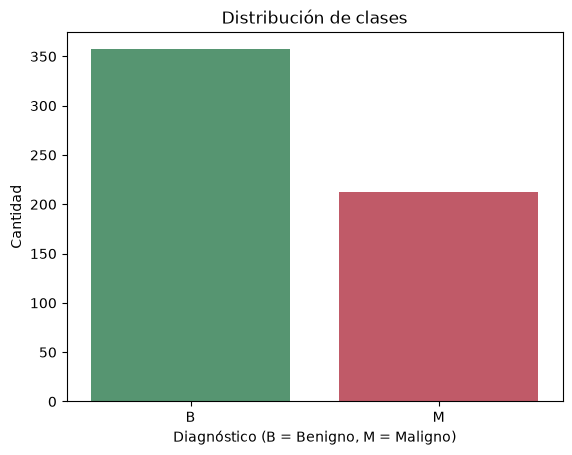


Forma de X: (569, 30)
Forma de y: (569,)


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# El archivo wdbc.data no tiene encabezados: se construyen según wdbc.names
# (10 medidas base x 3 estadísticos: mean, se, worst)
base = ['radius', 'texture', 'perimeter', 'area', 'smoothness',
        'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
columnas = ['id', 'diagnosis'] + [f'{c}_{s}' for s in ['mean', 'se', 'worst'] for c in base]

df = pd.read_csv('data/wdbc.data', header=None, names=columnas)

# --- Características generales ---
print("Cantidad de registros:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])
print("Variables predictoras:", df.shape[1] - 2, "(se excluyen 'id' y 'diagnosis')")
print("Valores nulos totales:", df.isnull().sum().sum())
print("\nClases a predecir (B = Benigno, M = Maligno):")
print(df['diagnosis'].value_counts())
print((df['diagnosis'].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

display(df.head())
display(df.describe().T)

# --- Gráfica de balance de clases ---
sns.countplot(x='diagnosis', hue='diagnosis', data=df,
              order=['B', 'M'],
              palette={'B': '#4C9F70', 'M': '#D1495B'},
              legend=False)
plt.title('Distribución de clases')
plt.xlabel('Diagnóstico (B = Benigno, M = Maligno)')
plt.ylabel('Cantidad')
plt.show()

# --- Separación de características y variable objetivo ---
X = df.drop(columns=['id', 'diagnosis'])
y = df['diagnosis'].map({'B': 0, 'M': 1})   # 0 = Benigno, 1 = Maligno (clase positiva)

print("\nForma de X:", X.shape)
print("Forma de y:", y.shape)

# Integrante 2: Preprocesamiento, evaluación común y KNN

Tareas: dividir los datos una sola vez para los tres modelos, estandarizar, crear la función de evaluación que usarán los demás, y entrenar KNN.

Entrenamiento: (455, 30) | Prueba: (114, 30)
Mejores hiperparámetros KNN: {'n_neighbors': 3, 'weights': 'uniform'}
===== KNN =====
              precision    recall  f1-score   support

     Benigno       0.92      0.99      0.95        72
     Maligno       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



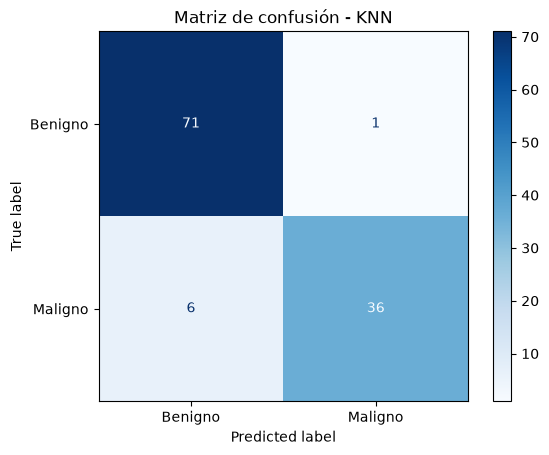

In [7]:
# ===== INTEGRANTE 2: PREPROCESAMIENTO + KNN =====
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

# --- División única para los tres algoritmos ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

# --- Estandarización (el scaler se ajusta SOLO con entrenamiento) ---
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# --- Función de evaluación común (la usan los integrantes 3 y 4) ---
resultados = []

def evaluar_modelo(nombre, modelo, X_te, y_te):
    """Evalúa un modelo ya entrenado y guarda sus métricas en 'resultados'.
    Clase positiva = Maligno (1)."""
    y_pred = modelo.predict(X_te)
    cm = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()

    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall': recall_score(y_te, y_pred),
        'F1-score': f1_score(y_te, y_pred),
        'Falsos positivos': fp,
        'Falsos negativos': fn,
        'Errores totales': fp + fn
    })

    print(f"===== {nombre} =====")
    print(classification_report(y_te, y_pred, target_names=['Benigno', 'Maligno']))
    ConfusionMatrixDisplay(cm, display_labels=['Benigno', 'Maligno']).plot(cmap='Blues')
    plt.title(f'Matriz de confusión - {nombre}')
    plt.show()
    return y_pred

# --- KNN: se busca el mejor k con validación cruzada sobre entrenamiento ---
param_knn = {'n_neighbors': list(range(1, 22, 2)),
             'weights': ['uniform', 'distance']}
grid_knn = GridSearchCV(KNeighborsClassifier(), param_knn, cv=5, scoring='accuracy')
grid_knn.fit(X_train_s, y_train)

knn = grid_knn.best_estimator_
print("Mejores hiperparámetros KNN:", grid_knn.best_params_)

y_pred_knn = evaluar_modelo('KNN', knn, X_test_s, y_test)

### Integrante 3: SVM

Tareas: entrenar SVM con búsqueda de hiperparámetros y evaluarlo con los mismos datos de prueba.

Mejores hiperparámetros SVM: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
===== SVM =====
              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



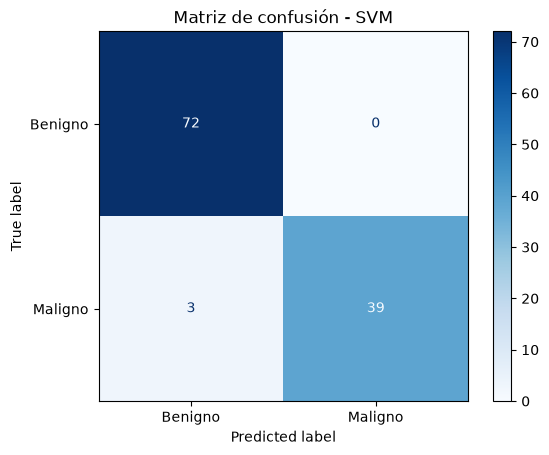

Vectores de soporte por clase: [50 57]


In [8]:
# ===== INTEGRANTE 3: SVM =====
from sklearn.svm import SVC

param_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 0.1, 0.01, 0.001]
}
grid_svm = GridSearchCV(SVC(random_state=42), param_svm, cv=5, scoring='accuracy')
grid_svm.fit(X_train_s, y_train)

svm = grid_svm.best_estimator_
print("Mejores hiperparámetros SVM:", grid_svm.best_params_)

y_pred_svm = evaluar_modelo('SVM', svm, X_test_s, y_test)
print("Vectores de soporte por clase:", svm.n_support_)

## Integrante 4: Neurona roja (MLP)

Tareas: entrene el MLP, muestre su curva de pérdida y evalúelo con los mismos datos de prueba.

Mejores hiperparámetros MLP: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (32,)}


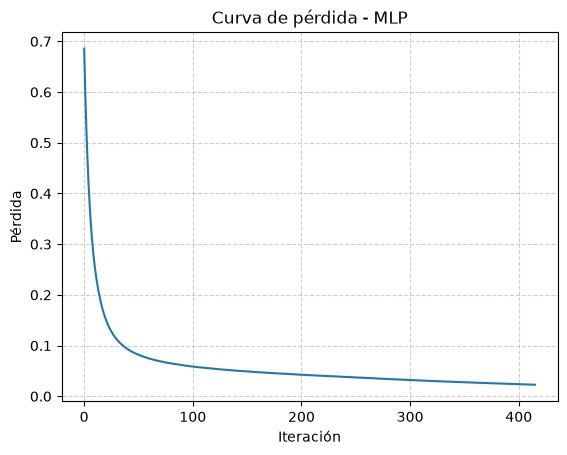

===== MLP =====
              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        72
     Maligno       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



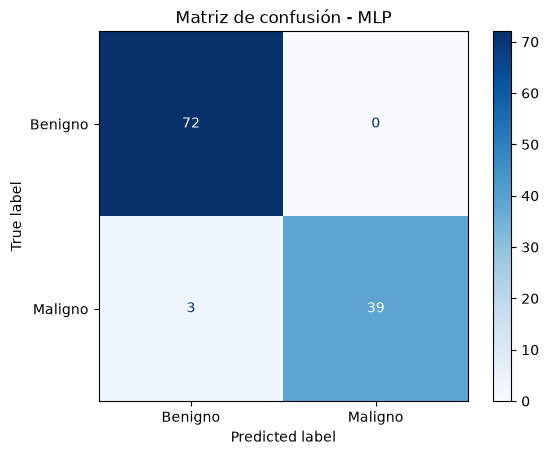

In [9]:
# ===== INTEGRANTE 4: RED NEURONAL (MLP) =====
from sklearn.neural_network import MLPClassifier

param_mlp = {
    'hidden_layer_sizes': [(16,), (32,), (32, 16), (64, 32)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01]
}

grid_mlp = GridSearchCV(
    MLPClassifier(max_iter=2000, random_state=42),
    param_mlp,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_mlp.fit(X_train_s, y_train)
mlp = grid_mlp.best_estimator_

print("Mejores hiperparámetros MLP:", grid_mlp.best_params_)

# Curva de pérdida durante el entrenamiento
plt.plot(mlp.loss_curve_)
plt.title('Curva de pérdida - MLP')
plt.xlabel('Iteración')
plt.ylabel('Pérdida')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Evaluación en el conjunto de prueba
y_pred_mlp = evaluar_modelo('MLP', mlp, X_test_s, y_test)

## Integrante 5: Comparación, gráficas y conclusiones

Tareas: reunir las métricas, generar la tabla y las gráficas, y redactar las respuestas con base en los resultados reales.

TABLA COMPARATIVA


,Accuracy,Precision,Recall,F1-score,Falsos positivos,Falsos negativos,Errores totales
Modelo,,,,,,,
KNN,0.9386,0.973,0.8571,0.9114,1,6,7
SVM,0.9737,1.000,0.9286,0.9630,0,3,3
MLP,0.9737,1.000,0.9286,0.9630,0,3,3


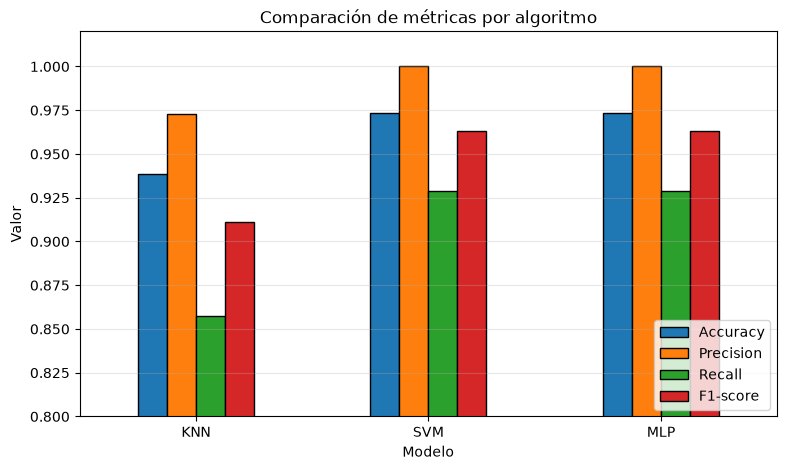

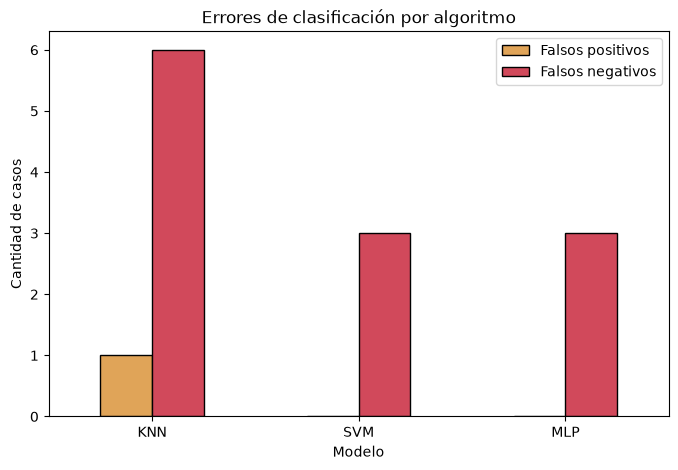

Mayor exactitud: SVM (0.9737)
Más errores totales: KNN (7 errores)
Mayor recall (menos tumores malignos sin detectar): SVM
Menos falsos negativos: SVM


In [10]:
# ===== INTEGRANTE 5: COMPARACIÓN Y CONCLUSIONES =====
tabla = pd.DataFrame(resultados).set_index('Modelo')
print("TABLA COMPARATIVA")
display(tabla.round(4))

# --- Gráfica 1: métricas por modelo ---
metricas = ['Accuracy', 'Precision', 'Recall', 'F1-score']
tabla[metricas].plot(kind='bar', figsize=(9, 5), ylim=(0.8, 1.02), edgecolor='black')
plt.title('Comparación de métricas por algoritmo')
plt.ylabel('Valor')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

# --- Gráfica 2: tipo de error por modelo ---
tabla[['Falsos positivos', 'Falsos negativos']].plot(
    kind='bar', figsize=(8, 5), color=['#E0A458', '#D1495B'], edgecolor='black')
plt.title('Errores de clasificación por algoritmo')
plt.ylabel('Cantidad de casos')
plt.xticks(rotation=0)
plt.show()

# --- Datos para responder las preguntas ---
mejor = tabla['Accuracy'].idxmax()
peor = tabla['Errores totales'].idxmax()
print(f"Mayor exactitud: {mejor} ({tabla.loc[mejor, 'Accuracy']:.4f})")
print(f"Más errores totales: {peor} ({tabla.loc[peor, 'Errores totales']} errores)")
print("Mayor recall (menos tumores malignos sin detectar):", tabla['Recall'].idxmax())
print("Menos falsos negativos:", tabla['Falsos negativos'].idxmin())

### 1. ¿Qué modelo tuvo mejor rendimiento?

SVM y MLP empataron con el mejor rendimiento: **accuracy de 0.9737** y **F1-score de 0.9630** cada uno. Los dos clasificaron bien 111 de los 114 casos de prueba. KNN quedó por debajo, con accuracy de 0.9386 y F1 de 0.9114.

La diferencia entre KNN y los otros dos modelos es de 4 casos (7 errores contra 3). Con 114 casos de prueba, cada error cambia la exactitud en unos 0.88 puntos porcentuales. Por eso la diferencia de KNN es real pero moderada, y entre SVM y MLP no hay ninguna diferencia en este conjunto de prueba. El código muestra solo a SVM como "mayor exactitud" porque `idxmax()` devuelve el primer modelo cuando hay empate.

### 2. ¿Qué modelo cometió más errores?

**KNN**, con **7 errores totales**: 1 falso positivo y **6 falsos negativos**. Casi todos sus errores fueron del tipo más grave: tumores malignos clasificados como benignos. Esto se ve en su recall de la clase maligna, que fue de 0.8571, el más bajo de los tres (detectó 36 de 42 malignos).

SVM y MLP cometieron 3 errores cada uno, y los tres fueron falsos negativos (0 falsos positivos).

### 3. Diferencias de comportamiento entre los algoritmos

- **KNN** no entrena un modelo propiamente dicho. Clasifica cada caso nuevo comparándolo con sus k vecinos más cercanos (aquí k = 3). Depende mucho de la escala de las variables, por eso se estandarizaron los datos. Con un k pequeño, los casos malignos que se parecen a los benignos quedan rodeados de vecinos benignos, lo que explica sus 6 falsos negativos.
- **SVM** busca la frontera que deja el margen máximo entre las dos clases. Con kernel RBF puede trazar fronteras no lineales. Suele ser estable y tener buen desempeño en datasets pequeños y con muchas variables, como este (569 registros, 30 variables).
- **MLP** aprende patrones no lineales combinando capas de neuronas (aquí una capa oculta de 32 neuronas con activación tanh). Es más flexible, pero sus resultados dependen de la inicialización aleatoria y de más hiperparámetros (arquitectura, activación, regularización, iteraciones), lo que lo hace más costoso de ajustar y menos interpretable.

### 4. ¿Conviene elegir simplemente el modelo con mayor exactitud?

No. En diagnóstico de tumores la exactitud no es suficiente, porque no distingue entre tipos de error. Un **falso negativo** (un tumor maligno clasificado como benigno) es mucho más grave que un falso positivo: retrasa el tratamiento del paciente. Un falso positivo, en cambio, solo genera estudios adicionales. Por eso hay que priorizar el **recall de la clase maligna** y revisar la matriz de confusión.

En este caso los dos criterios coinciden: SVM y MLP tienen la mayor exactitud (0.9737) y también el menor número de falsos negativos (3, con recall de 0.9286). KNN queda descartado por sus 6 falsos negativos.

Entre SVM y MLP, que empatan en todas las métricas, elegimos **SVM**: necesita menos hiperparámetros, no depende de la inicialización aleatoria y suele ser más estable en datasets pequeños. Aun así, ningún modelo llega a 0 falsos negativos. En un uso real convendría bajar el umbral de decisión para aumentar el recall de la clase maligna, aunque eso suba los falsos positivos.